# Лабораторная работа: линейная алгебра для Data Science


## Назначение работы

Эта лабораторная работа связывает базовые операции линейной алгебры с тем, как данные представлены и обрабатываются в Data Science. Сначала каждое действие выполняется аналитически, затем записывается математически в Markdown и только после этого проверяется с помощью NumPy. В заключительной части готовый код показывает базовую идею метода главных компонент (PCA) и сингулярного разложения (SVD): от студента требуется не программировать эти алгоритмы с нуля, а понимать входные данные, читать результат и объяснять его пользу.

Работа рассчитана на интенсивное занятие с обязательным домашним продолжением. На занятии следует пройти материал до раздела 8 включительно. Если какая-либо из предшествующих задач не завершена в аудитории, она также входит в домашнюю часть. Разделы 9 и 10 обязательны для самостоятельного завершения.

Основной источник теории — пособие [«Линейная алгебра»](../02-linear-algebra/linear-algebra.pdf). Из [«Высшей математики. Практикума»](../00-input/stuff/02-Высшая-математика-практикум.pdf) взята только часть стартовых аналитических условий. Остальные аналитические вопросы, задачи на общем наборе данных и вычислительные исследования специально составлены для этой работы по материалам пособия. Поэтому отсутствие ссылки на практикум означает не пропуск источника, а авторское задание внутри общей канвы.


## Как работать с материалом

Каждый этап помечен способом работы:

- **[Бумага]** — решить аналитически без NumPy;
- **[Markdown]** — перенести ход решения в Markdown-ячейку ноутбука, используя LaTeX;
- **[Python]** — проверить вычисления или выполнить готовый вычислительный фрагмент;
- **[Интерпретация]** — объяснить результат обычными словами применительно к данным.

Ответ считается полным, если виден не только итог, но и ход рассуждения: исходные объекты, используемое правило, промежуточные вычисления, проверка и смысл результата. Десятичное число не заменяет точное значение, если ответ естественно выражается дробью, корнем или углом.


### Единая канва

Мы будем двигаться по одной цепочке:

1. вектор описывает один объект;
2. норма и скалярное произведение сравнивают векторы;
3. матрица собирает много объектов в набор данных;
4. матричные операции преобразуют этот набор;
5. линейное отображение переводит признаки в новое представление;
6. определитель и ранг показывают, не потеряна ли информация;
7. система уравнений восстанавливает неизвестные параметры;
8. метод наименьших квадратов даёт лучшее приближённое решение, если точного нет;
9. PCA оставляет наиболее информативные направления;
10. SVD строит малоранговые приближения и позволяет оценить компромисс между точностью и объёмом хранения.

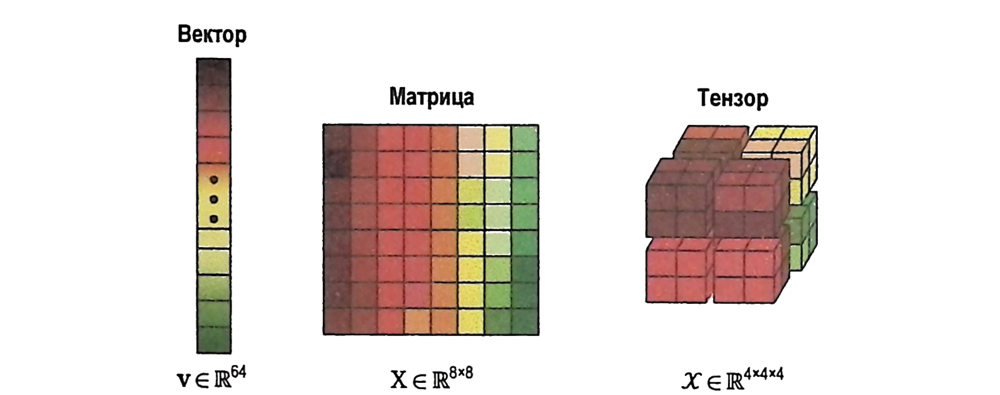

*Представление чисел в виде вектора, матрицы и тензора. Подробная подпись приведена в теоретическом пособии на с. 5.*


## Общий набор данных

Во всех вычислительных разделах используются сведения об учебной активности восьми студентов. Строка соответствует студенту, первый столбец — числу часов практики за условный период, второй — числу выполненных комплектов упражнений, а отдельный вектор $\mathbf y$ содержит итоговый балл.

| Студент | Часы практики | Комплекты упражнений | Итоговый балл |
|---|---:|---:|---:|
| Аня | 1 | 2 | 48 |
| Борис | 2 | 2 | 52 |
| Вера | 2 | 3 | 55 |
| Глеб | 3 | 4 | 63 |
| Дина | 4 | 5 | 70 |
| Егор | 5 | 7 | 78 |
| Жанна | 6 | 8 | 85 |
| Илья | 7 | 10 | 94 |

Матрица признаков и вектор результата имеют вид

$$
\mathbf X=
\begin{pmatrix}
1&2\\
2&2\\
2&3\\
3&4\\
4&5\\
5&7\\
6&8\\
7&10
\end{pmatrix}\in\mathbb R^{8\times2},
\qquad
\mathbf y=
\begin{pmatrix}
48\\52\\55\\63\\70\\78\\85\\94
\end{pmatrix}\in\mathbb R^8.
$$

Набор специально мал: все существенные действия можно понять вручную, а затем увидеть тот же язык линейной алгебры в коде.


In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)

student_names = np.array(["Аня", "Борис", "Вера", "Глеб", "Дина", "Егор", "Жанна", "Илья"])
X = np.array([
    [1, 2],
    [2, 2],
    [2, 3],
    [3, 4],
    [4, 5],
    [5, 7],
    [6, 8],
    [7, 10],
], dtype=float)
y = np.array([48, 52, 55, 63, 70, 78, 85, 94], dtype=float)

print("X.shape =", X.shape)
print("y.shape =", y.shape)
print("Первые две строки X:\n", X[:2])


X.shape = (8, 2)
y.shape = (8,)
Первые две строки X:
 [[1. 2.]
 [2. 2.]]


## 1. Векторы: координаты, длина, угол и ортогональность


### Короткая теория

Вектор-столбец из $n$ действительных чисел обозначается $\mathbf x\in\mathbb R^n$. Его евклидова норма и скалярное произведение задаются формулами

$$
\lVert\mathbf x\rVert_2=\sqrt{\sum_{i=1}^{n}x_i^2},
\qquad
\langle\mathbf x,\mathbf y\rangle=\mathbf x^{\mathsf T}\mathbf y
=\sum_{i=1}^{n}x_i y_i.
$$

Если оба вектора ненулевые, угол $\varphi$ между ними определяется равенством

$$
\cos\varphi=
\frac{\langle\mathbf x,\mathbf y\rangle}
{\lVert\mathbf x\rVert_2\lVert\mathbf y\rVert_2}.
$$

При $\langle\mathbf x,\mathbf y\rangle=0$ векторы ортогональны. См. [обозначения векторов, с. 4](../02-linear-algebra/linear-algebra.pdf#page=4), [нормы, с. 8](../02-linear-algebra/linear-algebra.pdf#page=8) и [скалярное произведение и угол, с. 14–15](../02-linear-algebra/linear-algebra.pdf#page=14).

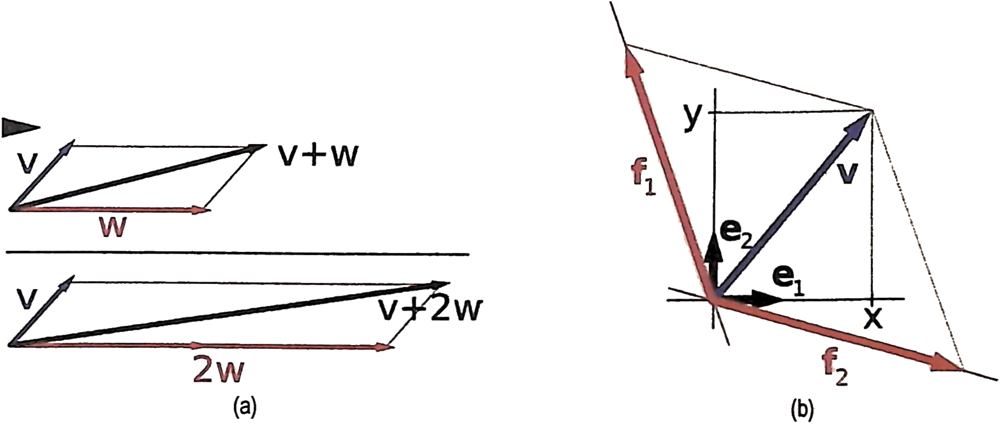

*Сложение, умножение на скаляр и представление вектора в разных базисах.*


### Задание 1.1. Координаты и длина

Источник условия: [практикум, с. 40, задача 3](../00-input/stuff/02-Высшая-математика-практикум.pdf#page=40).

Даны точки $A(1,2,3)$ и $B(3,-4,6)$. Найдите координаты вектора $\overrightarrow{AB}$ и его длину.

- **[Бумага]** Запишите правило $\overrightarrow{AB}=B-A$, выполните вычитание по координатам и вычислите норму.
- **[Markdown]** Перенесите полную выкладку, сохранив точное значение нормы.
- **[Python]** Создайте массивы `A` и `B`, затем проверьте результат с помощью вычитания и `np.linalg.norm`.
- **[Интерпретация]** Объясните, что означает направление $A\to B$ и почему длина не может быть отрицательной.


#### Ваше решение

**Аналитическая выкладка.**
$$\overrightarrow{AB}=B-A=(3-1,-4-2,6-3)=(2,-6,3).$$
$$\|\overrightarrow{AB}\|_2=\sqrt{2^2+(-6)^2+3^2}=\sqrt{49}=7.$$
**Проверка и интерпретация.** NumPy даёт $(2,-6,3)$ и 7. Вектор задаёт перемещение из A в B: +2, −6, +3 по осям. Длина — расстояние, квадратный корень из неотрицательной суммы квадратов.

In [2]:
A_point = np.array([1, 2, 3], dtype=float)
B_point = np.array([3, -4, 6], dtype=float)

AB = B_point - A_point
length_AB = np.linalg.norm(AB)
print(AB, length_AB)

[ 2. -6.  3.] 7.0


### Задание 1.2. Угол между векторами

Источник условия: [практикум, с. 39, задача 1](../00-input/stuff/02-Высшая-математика-практикум.pdf#page=39).

Найдите угол между векторами

$$
\mathbf a=(-1,1,0)^{\mathsf T},
\qquad
\mathbf b=(1,-2,2)^{\mathsf T}.
$$

- **[Бумага]** Найдите скалярное произведение, обе нормы, $\cos\varphi$ и угол в градусах.
- **[Markdown]** Покажите подстановку в формулу, а не только значение угла.
- **[Python]** Проверьте вычисление через `np.dot`, `np.linalg.norm`, `np.clip`, `np.arccos` и `np.degrees`.
- **[Интерпретация]** По знаку скалярного произведения определите, является угол острым, прямым или тупым.


#### Ваше решение

**Аналитическая выкладка.**
$$a^Tb=(-1)\cdot1+1\cdot(-2)+0\cdot2=-3,$$
$$\|a\|=\sqrt{1+1}=\sqrt2,\quad \|b\|=\sqrt{1+4+4}=3.$$
$$\cos\varphi=\frac{-3}{3\sqrt2}=-\frac{1}{\sqrt2},\quad \varphi=\arccos(-1/\sqrt2)=135^\circ.$$
**Проверка и интерпретация.** Код подтверждает −3 и 135°. Отрицательное скалярное произведение означает тупой угол.

In [3]:
a = np.array([-1, 1, 0], dtype=float)
b = np.array([1, -2, 2], dtype=float)

dot = np.dot(a, b)
norm_a, norm_b = np.linalg.norm(a), np.linalg.norm(b)
cos_phi = np.clip(dot / (norm_a * norm_b), -1.0, 1.0)
phi_degrees = np.degrees(np.arccos(cos_phi))
print(dot, norm_a, norm_b, cos_phi, phi_degrees)

-3.0 1.4142135623730951 3.0 -0.7071067811865475 135.0


### Задание 1.3. Ортогональность

Источник условия: [практикум, с. 39, задача 2](../00-input/stuff/02-Высшая-математика-практикум.pdf#page=39).

При каком значении $x$ векторы

$$
\mathbf a=(3,2,-1)^{\mathsf T},
\qquad
\mathbf b=(2,x,2)^{\mathsf T}
$$

ортогональны?

- **[Бумага]** Приравняйте $\mathbf a^{\mathsf T}\mathbf b$ к нулю и решите скалярное уравнение.
- **[Markdown]** Запишите проверку найденного значения подстановкой.
- **[Python]** Соберите вектор $\mathbf b$ с найденным $x$ и вычислите `a @ b`.
- **[Интерпретация]** Объясните, почему нулевое скалярное произведение можно рассматривать как отсутствие линейной согласованности направлений.


#### Ваше решение

**Аналитическая выкладка.**
$$a^Tb=3\cdot2+2x-1\cdot2=4+2x=0\Rightarrow x=-2.$$
Проверка: $6+2(-2)-2=0$.

**Проверка и интерпретация.** Скалярное произведение равно нулю: направления перпендикулярны, проекция одного на другое равна нулю. Это не обязательно означает статистическую независимость признаков.

In [4]:
a = np.array([3, 2, -1], dtype=float)
x_value = -2
b = np.array([2, x_value, 2], dtype=float)
print("a @ b =", a @ b)

a @ b = 0.0


### Задание 1.4. Векторы объектов в данных

- **[Бумага]** Запишите векторы признаков Ани и Ильи из общей таблицы. Найдите вектор изменения от Ани к Илье и его норму.
- **[Markdown]** Укажите единицы каждой координаты и объясните, почему смешанная евклидова норма здесь требует осторожной интерпретации.
- **[Python]** Повторите расчёт для первой и последней строк $\mathbf X$.
- **[Интерпретация]** Ответьте, зачем перед сравнением признаков с разными единицами измерения выполняют стандартизацию. К этому вопросу мы вернёмся в PCA.


#### Ваше решение

**Аналитическая выкладка.**
$$x_A=(1,2),\quad x_I=(7,10),\quad \Delta=x_I-x_A=(6,8),\quad \|\Delta\|=\sqrt{36+64}=10.$$
Первая координата — часы, вторая — комплекты упражнений.

**Проверка и интерпретация.** Код даёт (6, 8) и 10. Это числовое расстояние в смешанных единицах, не 10 часов или комплектов. Стандартизация вычитает среднее и делит на стандартное отклонение, делая масштабы сопоставимыми.

In [5]:
anya = X[0]
ilya = X[-1]

delta_activity = ilya - anya
distance_activity = np.linalg.norm(delta_activity)
print(delta_activity, distance_activity)

[6. 8.] 10.0


## 2. Матрица данных и матричные операции


### Короткая теория

Матрица $\mathbf A\in\mathbb R^{m\times n}$ содержит $m$ строк и $n$ столбцов. В нашей договорённости строки — наблюдения, столбцы — признаки. Матрицы одинакового размера складываются поэлементно, а умножение на скаляр масштабирует каждый элемент. Теорию обозначений см. на [с. 4–5](../02-linear-algebra/linear-algebra.pdf#page=4), а правила произведения матриц — на [с. 15–18](../02-linear-algebra/linear-algebra.pdf#page=15).

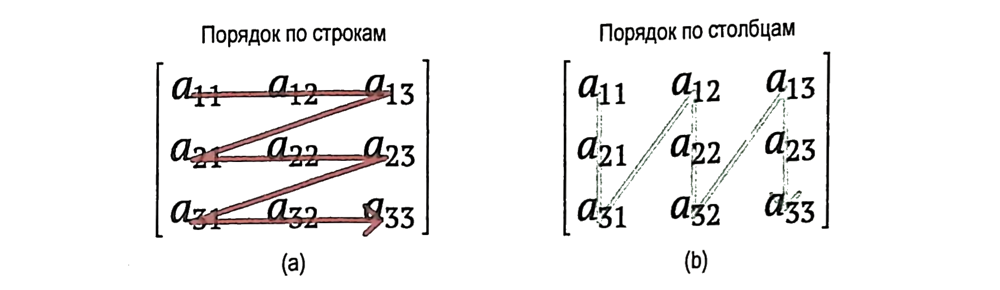

*Порядок обхода элементов по строкам и по столбцам. Для анализа данных особенно важно явно фиксировать, что обозначают оси массива.*


### Задание 2.1. Сложение матриц

Источник условия: [практикум, с. 18](../00-input/stuff/02-Высшая-математика-практикум.pdf#page=18).

Вычислите $\mathbf A+\mathbf B$, если

$$
\mathbf A=
\begin{pmatrix}
3&5&7\\2&-1&0\\4&3&2
\end{pmatrix},
\qquad
\mathbf B=
\begin{pmatrix}
1&2&4\\2&3&-2\\-1&0&1
\end{pmatrix}.
$$

- **[Бумага]** Выполните сложение поэлементно.
- **[Markdown]** Покажите исходные матрицы и итоговую матрицу.
- **[Python]** Проверьте результат оператором `+`.
- **[Интерпретация]** Приведите пример, когда складывать две матрицы данных осмысленно, и пример, когда одинакового размера недостаточно из-за разного смысла столбцов.


#### Ваше решение

**Аналитическая выкладка.** Складываем соответствующие элементы:
$$\begin{pmatrix}3&5&7\\2&-1&0\\4&3&2\end{pmatrix}+\begin{pmatrix}1&2&4\\2&3&-2\\-1&0&1\end{pmatrix}=\begin{pmatrix}3+1&5+2&7+4\\2+2&-1+3&0-2\\4-1&3+0&2+1\end{pmatrix}=\begin{pmatrix}4&7&11\\4&2&-2\\3&3&3\end{pmatrix}.$$
**Проверка и интерпретация.** Результат NumPy совпадает. Можно сложить часы и комплекты одних студентов за две недели при одинаковом порядке строк и столбцов. Нельзя осмысленно складывать часы с баллами только потому, что размеры матриц одинаковы.

In [6]:
A = np.array([[3, 5, 7], [2, -1, 0], [4, 3, 2]])
B = np.array([[1, 2, 4], [2, 3, -2], [-1, 0, 1]])

result_sum = A + B
print(result_sum)

[[ 4  7 11]
 [ 4  2 -2]
 [ 3  3  3]]


### Задание 2.2. Линейная комбинация матриц

Источник условия: [практикум, с. 18](../00-input/stuff/02-Высшая-математика-практикум.pdf#page=18).

Вычислите $2\mathbf A+5\mathbf B$, если

$$
\mathbf A=
\begin{pmatrix}3&5\\4&1\end{pmatrix},
\qquad
\mathbf B=
\begin{pmatrix}2&3\\1&-2\end{pmatrix}.
$$

- **[Бумага]** Сначала умножьте каждую матрицу на её коэффициент, затем сложите.
- **[Markdown]** Сохраните один промежуточный шаг.
- **[Python]** Проверьте выражением `2 * A + 5 * B`.
- **[Интерпретация]** Объясните линейную комбинацию как взвешенное объединение двух источников числового сигнала.


#### Ваше решение

**Аналитическая выкладка.**
$$2A+5B=\begin{pmatrix}6&10\\8&2\end{pmatrix}+\begin{pmatrix}10&15\\5&-10\end{pmatrix}=\begin{pmatrix}16&25\\13&-8\end{pmatrix}.$$
**Проверка и интерпретация.** Код подтверждает матрицу. Коэффициенты 2 и 5 задают веса двух согласованных источников сигнала: при одинаковом масштабе второй влияет на сумму сильнее.

In [7]:
A = np.array([[3, 5], [4, 1]])
B = np.array([[2, 3], [1, -2]])

result_combination = 2 * A + 5 * B
print(result_combination)

[[16 25]
 [13 -8]]


### Задание 2.3. Произведение матриц и порядок множителей

Источник условия: [практикум, с. 19](../00-input/stuff/02-Высшая-математика-практикум.pdf#page=19).

Для матриц

$$
\mathbf A=
\begin{pmatrix}
1&3&1\\2&0&4\\1&2&3
\end{pmatrix},
\qquad
\mathbf B=
\begin{pmatrix}
2&1&0\\1&-1&2\\3&2&1
\end{pmatrix}
$$

найдите $\mathbf A\mathbf B$ и $\mathbf B\mathbf A$.

- **[Бумага]** Для элемента $(1,1)$ каждого произведения явно покажите скалярное произведение строки и столбца. Затем заполните обе матрицы.
- **[Markdown]** Сопоставьте результаты и сформулируйте вывод о перестановочности.
- **[Python]** Проверьте оба произведения оператором `@` и сравните их через `np.array_equal`.
- **[Интерпретация]** Объясните, почему «сначала преобразование $\mathbf B$, затем $\mathbf A$» в общем случае отличается от обратного порядка.

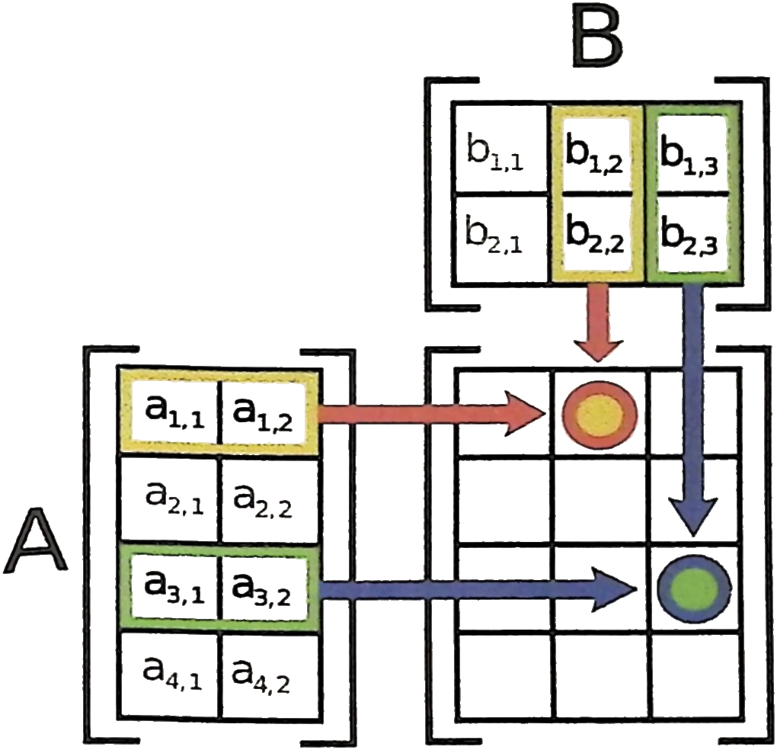

*Элемент произведения получается скалярным произведением соответствующей строки и столбца.*


#### Ваше решение

**Аналитическая выкладка.**
$$(AB)_{11}=1\cdot2+3\cdot1+1\cdot3=8,\quad (BA)_{11}=2\cdot1+1\cdot2+0\cdot1=4.$$
Остальные элементы вычисляем аналогично, умножая строки на столбцы:
$$AB=\begin{pmatrix}8&0&7\\16&10&4\\13&5&7\end{pmatrix},\quad BA=\begin{pmatrix}4&6&6\\1&7&3\\8&11&14\end{pmatrix}.$$
**Проверка и интерпретация.** `array_equal` возвращает False. Умножение матриц в общем случае некоммутативно: $ABx=A(Bx)$, а $BAx=B(Ax)$, поэтому порядок преобразований меняет результат.

In [8]:
A = np.array([[1, 3, 1], [2, 0, 4], [1, 2, 3]])
B = np.array([[2, 1, 0], [1, -1, 2], [3, 2, 1]])

AB = A @ B
BA = B @ A
print("AB =\n", AB)
print("BA =\n", BA)
print("AB == BA:", np.array_equal(AB, BA))

AB =
 [[ 8  0  7]
 [16 10  4]
 [13  5  7]]
BA =
 [[ 4  6  6]
 [ 1  7  3]
 [ 8 11 14]]
AB == BA: False


### Задание 2.4. Размерность матрицы данных

- **[Markdown]** Для $\mathbf X\in\mathbb R^{8\times2}$ подпишите смысл числа 8 и числа 2. Для $\mathbf y\in\mathbb R^8$ объясните соответствие элементов строкам $\mathbf X$.
- **[Python]** Выведите `X.shape`, `y.shape`, средние значения столбцов и матрицу $\mathbf X^{\mathsf T}\mathbf X$.
- **[Интерпретация]** Объясните, почему перестановка двух столбцов меняет смысл коэффициентов будущей модели, хотя число строк сохраняется.


#### Ваше решение

**Аналитическая выкладка / наблюдения.** $X\in\mathbb R^{8\times2}$: 8 студентов, 2 признака (часы и комплекты). $y\in\mathbb R^8$: каждый балл соответствует строке X с тем же индексом.
$$\bar X=(30/8,41/8)=(3.75,5.125),\quad X^TX=\begin{pmatrix}144&197\\197&271\end{pmatrix}.$$
**Проверка и интерпретация.** Код подтверждает размеры (8, 2), (8,) и числа. При перестановке столбцов необходимо переставить соответствующие коэффициенты модели: иначе коэффициент часов будет применён к комплектам и наоборот.

In [9]:
print("X.shape =", X.shape, "; y.shape =", y.shape)

print("Средние =", X.mean(axis=0))
print("X.T @ X =\n", X.T @ X)

X.shape = (8, 2) ; y.shape = (8,)
Средние = [3.75  5.125]
X.T @ X =
 [[144. 197.]
 [197. 271.]]


## 3. Линейные отображения


### Короткая теория

Линейное отображение в координатах записывается как

$$
\mathbf y=\mathbf A\mathbf x.
$$

Столбцы $\mathbf A$ показывают, куда переходят базисные векторы. Отображение сохраняет сложение и умножение на скаляр. См. [теорию, с. 7–8](../02-linear-algebra/linear-algebra.pdf#page=7).

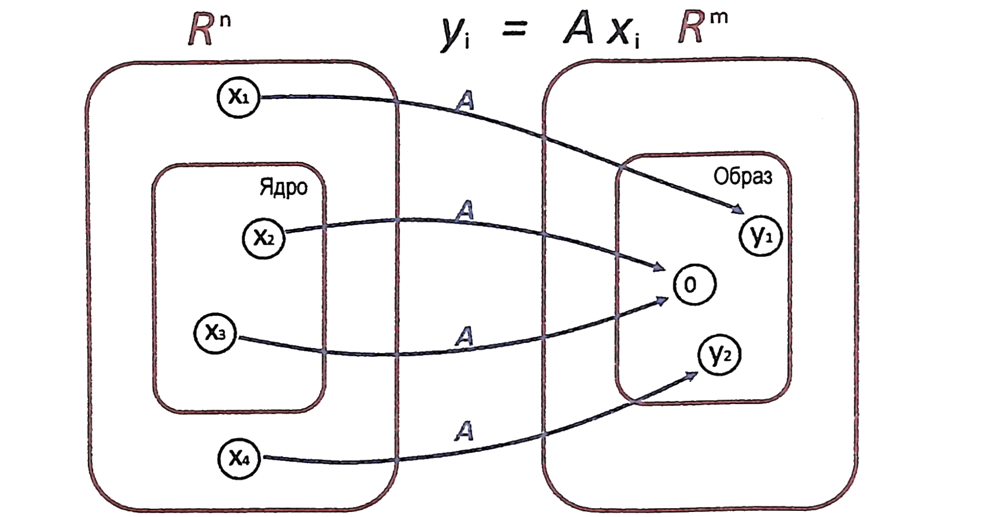

*Матрица переводит векторы области определения в образ; векторы ядра переходят в нулевой вектор.*


### Задание 3.1. Матрица преобразования

Источник условия: [практикум, с. 45, задача 1а](../00-input/stuff/02-Высшая-математика-практикум.pdf#page=45).

Линейное преобразование задано правилом

$$
\mathcal A(\mathbf x)=
\begin{pmatrix}
x_2-x_3\\x_1\\x_1+x_3
\end{pmatrix}.
$$

Найдите матрицу этого преобразования в стандартном базисе.

- **[Бумага]** Найдите $\mathcal A(\mathbf e_1)$, $\mathcal A(\mathbf e_2)$ и $\mathcal A(\mathbf e_3)$ и поместите полученные векторы в столбцы.
- **[Markdown]** Проверьте полученную матрицу символическим умножением на $(x_1,x_2,x_3)^{\mathsf T}$.
- **[Python]** Умножьте матрицу на несколько тестовых векторов и сопоставьте с исходным правилом.
- **[Интерпретация]** Объясните, почему каждый выходной признак является линейной комбинацией входных.


#### Ваше решение

**Аналитическая выкладка.** Для стандартных базисных векторов получаем $\mathcal A(e_1)=(0,1,1)^T$, $\mathcal A(e_2)=(1,0,0)^T$, $\mathcal A(e_3)=(-1,0,1)^T$.
$$T=\begin{pmatrix}0&1&-1\\1&0&0\\1&0&1\end{pmatrix},\quad T\begin{pmatrix}x_1\\x_2\\x_3\end{pmatrix}=\begin{pmatrix}x_2-x_3\\x_1\\x_1+x_3\end{pmatrix}.$$
**Проверка и интерпретация.** Все тесты совпадают с исходным правилом, в том числе для (2,3,4) получается (−1,2,6). Каждый выходной признак — взвешенная сумма входных без свободного члена.

In [10]:
T = np.array([[0, 1, -1], [1, 0, 0], [1, 0, 1]])
test_vectors = np.vstack([np.eye(3), [2, 3, 4]])
for x in test_vectors:
    expected = np.array([x[1]-x[2], x[0], x[0]+x[2]])
    print(x, T @ x, expected, np.allclose(T @ x, expected))

[1. 0. 0.] [0. 1. 1.] [0. 1. 1.] True
[0. 1. 0.] [1. 0. 0.] [1. 0. 0.] True
[0. 0. 1.] [-1.  0.  1.] [-1.  0.  1.] True
[2. 3. 4.] [-1.  2.  6.] [-1.  2.  6.] True


### Задание 3.2. Образ вектора

Источник условия: [практикум, с. 46, задача 2а](../00-input/stuff/02-Высшая-математика-практикум.pdf#page=46).

Найдите образ вектора $\mathbf a=(1,-2,3)^{\mathsf T}$ при отображении с матрицей

$$
\mathbf A=
\begin{pmatrix}
1&-1&0\\3&0&1\\1&1&-2
\end{pmatrix}.
$$

- **[Бумага]** Вычислите $\mathbf A\mathbf a$ строка за строкой.
- **[Markdown]** Запишите произведение и итоговый вектор.
- **[Python]** Проверьте оператором `@`.
- **[Интерпретация]** Представьте, что $\mathbf a$ — три исходных признака, а строки $\mathbf A$ — правила создания трёх новых признаков. Расшифруйте первое правило словами.


#### Ваше решение

**Аналитическая выкладка.**
$$Aa=\begin{pmatrix}1&-1&0\\3&0&1\\1&1&-2\end{pmatrix}\begin{pmatrix}1\\-2\\3\end{pmatrix}=\begin{pmatrix}1+2+0\\3+0+3\\1-2-6\end{pmatrix}=\begin{pmatrix}3\\6\\-7\end{pmatrix}.$$
**Проверка и интерпретация.** NumPy подтверждает (3,6,−7). Первый новый признак — разность первого и второго исходных, третий исходный признак на него не влияет.

In [11]:
A = np.array([[1, -1, 0], [3, 0, 1], [1, 1, -2]])
a = np.array([1, -2, 3])

image_a = A @ a
print(image_a)

[ 3  6 -7]


## 4. Определитель и ранг: сохранена ли информация


### Короткая теория

Определитель квадратной матрицы показывает коэффициент изменения ориентированного объёма при линейном отображении. Если $\det(\mathbf A)=0$, матрица вырождена и обратной матрицы не существует. Ранг — размерность пространства, натянутого на строки или столбцы матрицы. Он показывает число линейно независимых направлений. См. [определитель, с. 10–11](../02-linear-algebra/linear-algebra.pdf#page=10) и [ранг, с. 11–12](../02-linear-algebra/linear-algebra.pdf#page=11).


### Задание 4.1. Определитель

Источник условия: [практикум, с. 16, задача 1](../00-input/stuff/02-Высшая-математика-практикум.pdf#page=16).

Вычислите

$$
\det
\begin{pmatrix}
5&2&3\\-4&3&5\\2&3&4
\end{pmatrix}.
$$

- **[Бумага]** Разложите определитель по первой строке и покажите три минора.
- **[Markdown]** Запишите полный расчёт со знаками алгебраических дополнений.
- **[Python]** Проверьте через `np.linalg.det`. Помните, что вычисление с плавающей точкой может дать число, очень близкое к целому.
- **[Интерпретация]** Сделайте вывод об обратимости и о том, схлопывает ли отображение трёхмерный объём.


#### Ваше решение

**Аналитическая выкладка.** Разложение по первой строке:
$$\det A=5\begin{vmatrix}3&5\\3&4\end{vmatrix}-2\begin{vmatrix}-4&5\\2&4\end{vmatrix}+3\begin{vmatrix}-4&3\\2&3\end{vmatrix}$$
$$=5(12-15)-2(-16-10)+3(-12-6)=-15+52-54=-17.$$
**Проверка и интерпретация.** NumPy даёт приблизительно −17. Матрица обратима, объём не схлопывается: его модуль увеличивается в 17 раз, ориентация меняется.

In [12]:
A = np.array([[5, 2, 3], [-4, 3, 5], [2, 3, 4]], dtype=float)

det_A = np.linalg.det(A)
print(det_A, round(det_A))

-17.000000000000018 -17


### Задание 4.2. Ранг двух матриц

Источник условий: [практикум, с. 25, задачи 1 и 2](../00-input/stuff/02-Высшая-математика-практикум.pdf#page=25).

Найдите ранги матриц

$$
\mathbf A_1=
\begin{pmatrix}
1&2\\0&5\\-1&4\\1&1
\end{pmatrix},
\qquad
\mathbf A_2=
\begin{pmatrix}
3&-5&-1&-2\\
8&-6&3&-7\\
2&4&5&-3
\end{pmatrix}.
$$

- **[Бумага]** Приведите каждую матрицу к ступенчатому виду элементарными преобразованиями строк. Число ненулевых строк даст ранг.
- **[Markdown]** Покажите ключевые преобразования, достаточные для проверки ответа.
- **[Python]** Сравните с `np.linalg.matrix_rank`.
- **[Интерпретация]** Для каждой матрицы назовите максимальное возможное значение ранга и объясните, означает ли найденный ранг линейную зависимость столбцов.


#### Ваше решение

**Аналитическая выкладка.** Для $A_1$ применим $R_3\leftarrow R_3+R_1$, $R_4\leftarrow R_4-R_1$:
$$\begin{pmatrix}1&2\\0&5\\0&6\\0&-1\end{pmatrix}\longrightarrow\begin{pmatrix}1&2\\0&5\\0&0\\0&0\end{pmatrix}$$
($R_3\leftarrow R_3-\frac65 R_2$, $R_4\leftarrow R_4+\frac15R_2$). Ранг 2.

Для $A_2$ применим $R_2\leftarrow3R_2-8R_1$, $R_3\leftarrow3R_3-2R_1$:
$$\begin{pmatrix}3&-5&-1&-2\\0&22&17&-5\\0&22&17&-5\end{pmatrix}\xrightarrow{R_3\leftarrow R_3-R_2}\begin{pmatrix}3&-5&-1&-2\\0&22&17&-5\\0&0&0&0\end{pmatrix}.$$
Ранг 2.

**Проверка и интерпретация.** NumPy даёт 2 и 2. Максимальные ранги 2 и 3 соответственно. У $A_1$ оба столбца независимы; у $A_2$ четыре столбца зависимы, независимых направлений только два.

In [13]:
A1 = np.array([[1, 2], [0, 5], [-1, 4], [1, 1]], dtype=float)
A2 = np.array([[3, -5, -1, -2], [8, -6, 3, -7], [2, 4, 5, -3]], dtype=float)

print(np.linalg.matrix_rank(A1), np.linalg.matrix_rank(A2))

2 2


## 5. Базис и координаты


### Короткая теория

Базис пространства — линейно независимая система векторов, через которую единственным образом выражается каждый вектор пространства. В $\mathbb R^3$ три вектора образуют базис тогда и только тогда, когда матрица из этих столбцов имеет ранг 3. См. [теорию, с. 6–7](../02-linear-algebra/linear-algebra.pdf#page=6).


### Задание 5.1. Проверка базиса

Источник условия: [практикум, с. 43, задача 1б](../00-input/stuff/02-Высшая-математика-практикум.pdf#page=43).

Проверьте, образуют ли базис в $\mathbb R^3$ векторы

$$
\mathbf a=(0,1,2)^{\mathsf T},\quad
\mathbf b=(1,0,1)^{\mathsf T},\quad
\mathbf c=(-1,2,4)^{\mathsf T}.
$$

- **[Бумага]** Составьте матрицу из данных векторов-столбцов и проверьте её ранг или определитель.
- **[Markdown]** Сформулируйте вывод через линейную независимость.
- **[Python]** Проверьте ранг и определитель.
- **[Интерпретация]** Объясните, что потеряется, если три выбранных направления окажутся линейно зависимыми.


#### Ваше решение

**Аналитическая выкладка.**
$$B=[a\ b\ c]=\begin{pmatrix}0&1&-1\\1&0&2\\2&1&4\end{pmatrix},\quad \det B=-(4-4)-(1-0)=-1.$$
Определитель ненулевой, поэтому ранг 3, векторы линейно независимы и образуют базис $\mathbb R^3$.

**Проверка и интерпретация.** NumPy даёт ранг 3 и определитель −1. При зависимости направлений часть пространства нельзя было бы представить, а представимые векторы не имели бы единственных координат.

In [14]:
a = np.array([0, 1, 2])
b = np.array([1, 0, 1])
c = np.array([-1, 2, 4])
B = np.column_stack([a, b, c])

print(B, np.linalg.matrix_rank(B), np.linalg.det(B), sep="\n")

[[ 0  1 -1]
 [ 1  0  2]
 [ 2  1  4]]
3
-1.0


### Задание 5.2. Координаты в новом базисе

Источник условия: [практикум, с. 43, задача 2а](../00-input/stuff/02-Высшая-математика-практикум.pdf#page=43).

Разложите $\mathbf x=(1,-4,4)^{\mathsf T}$ по векторам

$$
\mathbf p=(2,1,-1)^{\mathsf T},\quad
\mathbf r=(1,-1,1)^{\mathsf T},\quad
\mathbf q=(0,3,2)^{\mathsf T}.
$$

- **[Бумага]** Введите коэффициенты $\alpha,\beta,\gamma$ в равенстве $\mathbf x=\alpha\mathbf p+\beta\mathbf r+\gamma\mathbf q$ и решите систему.
- **[Markdown]** Выполните обратную проверку линейной комбинацией.
- **[Python]** Решите матричное уравнение через `np.linalg.solve`.
- **[Интерпретация]** Объясните отличие самого геометрического вектора от его координат в выбранном базисе.


#### Ваше решение

**Аналитическая выкладка.** $x=\alpha p+\beta r+\gamma q$:
$$\begin{cases}2\alpha+\beta=1\\\alpha-\beta+3\gamma=-4\\-\alpha+\beta+2\gamma=4\end{cases}$$
Сумма последних двух уравнений даёт $5\gamma=0$, значит $\gamma=0$. Тогда $\alpha-\beta=-4$; складывая с первым, получаем $3\alpha=-3$, $\alpha=-1$, $\beta=3$.
$$-p+3r+0q=(-2,-1,1)+(3,-3,3)=(1,-4,4).$$
**Проверка и интерпретация.** Координаты в новом базисе (−1,3,0); обратное умножение даёт исходный вектор. Сам геометрический вектор не меняется, меняется его описание относительно базисных направлений.

In [15]:
p = np.array([2, 1, -1], dtype=float)
r = np.array([1, -1, 1], dtype=float)
q = np.array([0, 3, 2], dtype=float)
x = np.array([1, -4, 4], dtype=float)
B = np.column_stack([p, r, q])

coordinates = np.linalg.solve(B, x)
print(coordinates, B @ coordinates, sep="\n")

[-1.  3.  0.]
[ 1. -4.  4.]


## 6. Системы линейных уравнений


### Короткая теория

Система записывается компактно:

$$
\mathbf A\mathbf x=\mathbf b.
$$

Квадратная невырожденная матрица задаёт единственное решение. У недоопределённой системы неизвестных больше, чем независимых уравнений, поэтому обычно остаются свободные параметры. У переопределённой системы уравнений больше, чем неизвестных, и точного решения может не существовать. См. [теорию, с. 36–38](../02-linear-algebra/linear-algebra.pdf#page=36).

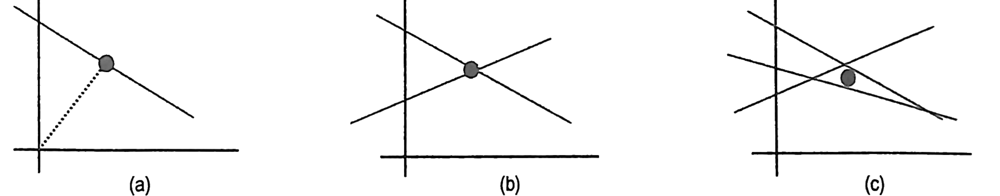

*Недоопределённая, квадратная и переопределённая системы в геометрическом представлении.*


### Задание 6.1. Квадратная система

Источник условия: [практикум, с. 34, задача 3](../00-input/stuff/02-Высшая-математика-практикум.pdf#page=34).

Решите методом Гаусса систему

$$
\begin{cases}
2x-y+z=2,\\
3x+2y+2z=-2,\\
x-2y+z=1.
\end{cases}
$$

- **[Бумага]** Запишите расширенную матрицу, приведите её к ступенчатому виду и выполните обратный ход.
- **[Markdown]** Покажите элементарные преобразования строк и подстановку решения в исходные уравнения.
- **[Python]** Проверьте через `np.linalg.solve` и вычислите невязку $\mathbf A\mathbf x-\mathbf b$.
- **[Интерпретация]** Объясните, почему нулевой вектор невязки означает точное выполнение всех уравнений.


#### Ваше решение

**Аналитическая выкладка.** Метод Гаусса. Поменяем первую и третью строки:
$$\left[\begin{array}{rrr|r}2&-1&1&2\\3&2&2&-2\\1&-2&1&1\end{array}\right]\to\left[\begin{array}{rrr|r}1&-2&1&1\\3&2&2&-2\\2&-1&1&2\end{array}\right].$$
$R_2\leftarrow R_2-3R_1$, $R_3\leftarrow R_3-2R_1$:
$$\left[\begin{array}{rrr|r}1&-2&1&1\\0&8&-1&-5\\0&3&-1&0\end{array}\right]\xrightarrow{R_3\leftarrow8R_3-3R_2}\left[\begin{array}{rrr|r}1&-2&1&1\\0&8&-1&-5\\0&0&-5&15\end{array}\right].$$
Обратный ход: $z=-3$, $8y+3=-5\Rightarrow y=-1$, $x+2-3=1\Rightarrow x=2$.

Проверка: $4+1-3=2$, $6-2-6=-2$, $2+2-3=1$.

**Проверка и интерпретация.** Решение (2,−1,−3), невязка близка к нулю. Каждая координата невязки — разность левой и правой частей соответствующего уравнения.

In [16]:
A = np.array([[2, -1, 1], [3, 2, 2], [1, -2, 1]], dtype=float)
b = np.array([2, -2, 1], dtype=float)

x = np.linalg.solve(A, b)
residual = A @ x - b
print(x, residual, sep="\n")

[ 2. -1. -3.]
[0. 0. 0.]


### Задание 6.2. Недоопределённая система

Источник условия: [практикум, с. 34, задача 1](../00-input/stuff/02-Высшая-математика-практикум.pdf#page=34).

Решите систему

$$
\begin{cases}
3x_1-4x_2+6x_3=-7,\\
2x_1+5x_2+4x_3=12.
\end{cases}
$$

- **[Бумага]** Положите $x_3=t$, выразите $x_1$ и $x_2$ через $t$ и запишите всё семейство решений.
- **[Markdown]** Проверьте обе строки системы символической подстановкой параметрического решения.
- **[Python]** Возьмите не менее трёх разных значений $t$ и убедитесь, что `A @ x - b` близко к нулю.
- **[Интерпретация]** Объясните, почему два независимых уравнения не определяют единственную точку в пространстве трёх неизвестных.


#### Ваше решение

**Аналитическая выкладка.** Пусть $x_3=t$:
$$3x_1-4x_2=-7-6t,\quad 2x_1+5x_2=12-4t.$$
Умножим первое на 5, второе на 4 и сложим: $23x_1=13-46t$, значит $x_1=13/23-2t$. Из второго $5x_2=12-26/23=250/23$, поэтому $x_2=50/23$.
$$x(t)=(13/23-2t,50/23,t)^T,\quad t\in\mathbb R.$$
Проверка: $3(13/23-2t)-4(50/23)+6t=-161/23=-7$; $2(13/23-2t)+5(50/23)+4t=276/23=12$.

**Проверка и интерпретация.** Для −2, 0, 3 невязки близки к нулю. Две независимые плоскости пересекаются по прямой, поэтому остаётся один свободный параметр.

In [17]:
A = np.array([[3, -4, 6], [2, 5, 4]], dtype=float)
b = np.array([-7, 12], dtype=float)
t_values = [-2.0, 0.0, 3.0]

for t in t_values:
    x = np.array([13/23 - 2*t, 50/23, t])
    print("t =", t, "x =", x, "невязка =", A @ x - b)

t = -2.0 x = [ 4.5652  2.1739 -2.    ] невязка = [0. 0.]
t = 0.0 x = [0.5652 2.1739 0.    ] невязка = [0. 0.]
t = 3.0 x = [-5.4348  2.1739  3.    ] невязка = [0. 0.]


## 7. Проекция


### Короткая теория

Проекция $\mathbf y$ на пространство столбцов $\mathbf A$ — ближайший к $\mathbf y$ вектор, который можно представить как $\mathbf A\mathbf x$:

$$
\operatorname{Proj}(\mathbf y;\mathbf A)
=\underset{\mathbf v\in\mathcal R(\mathbf A)}{\operatorname{argmin}}
\lVert\mathbf v-\mathbf y\rVert_2.
$$

Если столбцы $\mathbf A$ линейно независимы, то

$$
\widehat{\mathbf y}
=\mathbf A(\mathbf A^{\mathsf T}\mathbf A)^{-1}\mathbf A^{\mathsf T}\mathbf y.
$$

Разность $\mathbf e=\mathbf y-\widehat{\mathbf y}$ ортогональна пространству столбцов: $\mathbf A^{\mathsf T}\mathbf e=\mathbf0$. См. [теорию о проекции, с. 8](../02-linear-algebra/linear-algebra.pdf#page=8).


### Задание 7.1. Проекция на прямую

Пусть

$$
\mathbf y=(3,1)^{\mathsf T},
\qquad
\mathbf a=(1,1)^{\mathsf T}.
$$

- **[Бумага]** Найдите коэффициент $c=(\mathbf a^{\mathsf T}\mathbf y)/(\mathbf a^{\mathsf T}\mathbf a)$ и проекцию $\widehat{\mathbf y}=c\mathbf a$.
- **[Markdown]** Найдите остаток $\mathbf e=\mathbf y-\widehat{\mathbf y}$ и покажите, что $\mathbf a^{\mathsf T}\mathbf e=0$.
- **[Python]** Проверьте все вычисления и постройте векторы $\mathbf y$, $\widehat{\mathbf y}$ и $\mathbf e$ на плоскости.
- **[Интерпретация]** Объясните, почему проекция является лучшим приближением $\mathbf y$ точкой на прямой, натянутой на $\mathbf a$.


#### Ваше решение

**Аналитическая выкладка.**
$$c=\frac{a^Ty}{a^Ta}=\frac{3+1}{1+1}=2,\quad \widehat y=2a=(2,2)^T.$$
$$e=y-\widehat y=(1,-1)^T,\quad a^Te=1-1=0.$$
**Проверка и интерпретация.** Код подтверждает коэффициент 2 и ортогональность остатка. На графике остаток соединяет конец проекции с концом исходного вектора. По теореме Пифагора любая другая точка прямой дальше от y, чем его проекция.

2.0 [2. 2.] [ 1. -1.] 0.0


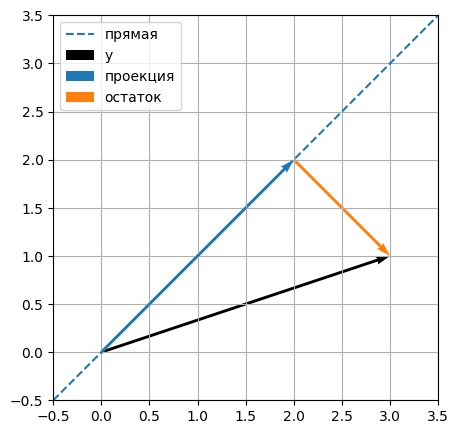

In [18]:
y_vector = np.array([3.0, 1.0])
a = np.array([1.0, 1.0])

coefficient = (a @ y_vector) / (a @ a)
y_projection = coefficient * a
residual = y_vector - y_projection
print(coefficient, y_projection, residual, a @ residual)
plt.figure(figsize=(5,5))
origin = np.zeros(2)
plt.plot([-0.5,3.5],[-0.5,3.5], '--', label="прямая")
plt.quiver(*origin, *y_vector, angles="xy", scale_units="xy", scale=1, label="y")
plt.quiver(*origin, *y_projection, angles="xy", scale_units="xy", scale=1, color="tab:blue", label="проекция")
plt.quiver(*y_projection, *residual, angles="xy", scale_units="xy", scale=1, color="tab:orange", label="остаток")
plt.xlim(-0.5,3.5); plt.ylim(-0.5,3.5); plt.grid(); plt.legend()
plt.gca().set_aspect("equal"); plt.show()

## 8. Метод наименьших квадратов: первая модель данных


### Короткая теория

Добавим к матрице признаков столбец единиц для свободного члена:

$$
\mathbf D=
\begin{pmatrix}
1&X_{11}&X_{12}\\
\vdots&\vdots&\vdots\\
1&X_{81}&X_{82}
\end{pmatrix},
\qquad
\boldsymbol\beta=
\begin{pmatrix}\beta_0\\\beta_1\\\beta_2\end{pmatrix}.
$$

Предсказания имеют вид $\widehat{\mathbf y}=\mathbf D\boldsymbol\beta$. Когда восемь уравнений для трёх коэффициентов нельзя выполнить точно одновременно, выбирают коэффициенты, минимизирующие сумму квадратов ошибок:

$$
\widehat{\boldsymbol\beta}
=\underset{\boldsymbol\beta}{\operatorname{argmin}}
\frac12\lVert\mathbf D\boldsymbol\beta-\mathbf y\rVert_2^2.
$$

Нормальные уравнения имеют вид

$$
\mathbf D^{\mathsf T}\mathbf D\widehat{\boldsymbol\beta}
=\mathbf D^{\mathsf T}\mathbf y.
$$

В вычислениях используем `numpy.linalg.lstsq`, поскольку явно формировать обратную матрицу не требуется и численно это обычно надёжнее. Теорию см. на [с. 38–39](../02-linear-algebra/linear-algebra.pdf#page=38).


### Задание 8.1. Матричная запись регрессии

- **[Бумага]** Выпишите первую и последнюю строки уравнения $\widehat{\mathbf y}=\mathbf D\boldsymbol\beta$ в скалярной форме.
- **[Markdown]** Объясните роли $\beta_0$, $\beta_1$ и $\beta_2$, указав единицы изменения итогового балла.
- **[Python]** Постройте $\mathbf D$, найдите коэффициенты командой `np.linalg.lstsq(D, y, rcond=None)` и вычислите $\widehat{\mathbf y}$.
- **[Интерпретация]** Объясните знак каждого коэффициента. Не трактуйте коэффициент как причинный эффект: это описание данного небольшого набора, а не эксперимент.


#### Ваше решение

**Аналитическая выкладка.** $D=[\mathbf 1\ X]\in\mathbb R^{8\times3}$, $\beta\in\mathbb R^3$.
Первая строка (Аня): $\widehat y_1=\beta_0+\beta_1+2\beta_2$. Последняя (Илья): $\widehat y_8=\beta_0+7\beta_1+10\beta_2$.

**Проверка и интерпретация.** Получена модель
$$\widehat y=38.9787+4.8936x_1+2.1064x_2.$$
Свободный член 38.9787 балла — прогноз при нулевых признаках, вне наблюдаемого диапазона. При фиксированном втором признаке дополнительный час связан с увеличением прогноза на 4.8936 балла; дополнительный комплект при фиксированных часах — на 2.1064 балла. Все коэффициенты положительны. Это ассоциации в восьми наблюдениях, а не доказанные причинные эффекты.

In [19]:
D = np.column_stack([np.ones(len(X)), X])

beta, *_ = np.linalg.lstsq(D, y, rcond=None)
y_hat = D @ beta
print("D.shape =", D.shape)
print("beta =", beta)
print("y_hat =", y_hat)

D.shape = (8, 3)
beta = [38.9787  4.8936  2.1064]
y_hat = [48.0851 52.9787 55.0851 62.0851 69.0851 78.1915 85.1915 94.2979]


### Задание 8.2. Невязка и качество приближения

- **[Бумага]** Для одного выбранного студента вычислите предсказание по найденной формуле и его остаток $e_i=y_i-\widehat y_i$.
- **[Markdown]** Запишите определения

  $$
  \operatorname{SSE}=\sum_i(y_i-\widehat y_i)^2,
  \qquad
  R^2=1-\frac{\sum_i(y_i-\widehat y_i)^2}{\sum_i(y_i-\overline y)^2}.
  $$

- **[Python]** Вычислите SSE, RMSE и $R^2$, постройте график «наблюдение — предсказание» и график остатков.
- **[Интерпретация]** Объясните, что значит высокое $R^2$ именно для этих восьми наблюдений и почему оно само по себе не гарантирует хорошее качество на новых данных.


#### Ваше решение

**Аналитическая выкладка.** Для Ани:
$$\widehat y_1=38.9787+4.8936+2\cdot2.1064\approx48.0851,\quad e_1=48-48.0851\approx-0.0851.$$
$$SSE=\sum_i(y_i-\widehat y_i)^2,\quad RMSE=\sqrt{SSE/8},\quad R^2=1-\frac{SSE}{\sum_i(y_i-\bar y)^2}.$$
**Проверка и интерпретация.** SSE ≈ 2.8085, RMSE ≈ 0.5925 балла, $R^2\approx0.99854$. Точки на графике близки к диагонали, остатки лежат примерно между −0.98 и 0.92 балла. Модель объясняет около 99.85% вариации баллов в этой выборке, но без проверки на новых данных нельзя гарантировать качество прогноза.

Остатки: [-0.0851 -0.9787 -0.0851  0.9149  0.9149 -0.1915 -0.1915 -0.2979]
SSE = 2.8085106382978715 RMSE = 0.5925063964103965 R2 = 0.9985363764506298


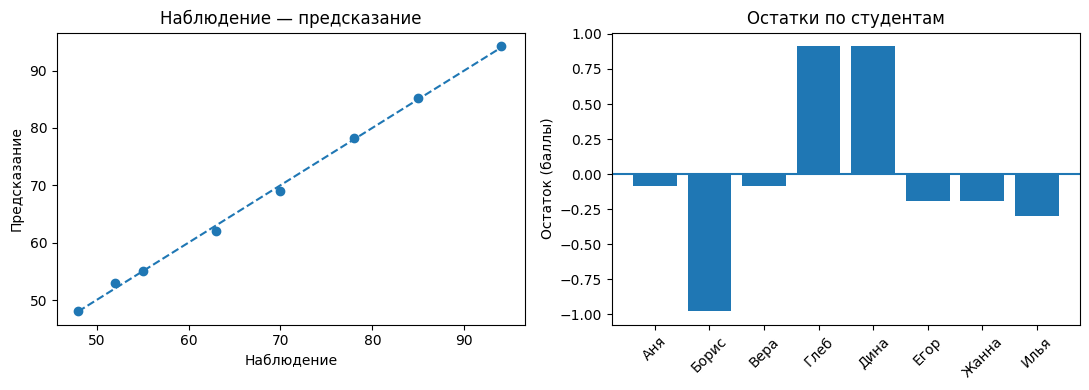

In [20]:
residuals = y - y_hat
SSE = np.sum(residuals**2)
RMSE = np.sqrt(SSE / len(y))
R2 = 1 - SSE / np.sum((y-y.mean())**2)
print("Остатки:", residuals)
print("SSE =", SSE, "RMSE =", RMSE, "R2 =", R2)
fig, axes = plt.subplots(1,2,figsize=(11,4))
axes[0].scatter(y,y_hat)
lo, hi = min(y.min(),y_hat.min()), max(y.max(),y_hat.max())
axes[0].plot([lo,hi],[lo,hi],'--')
axes[0].set(xlabel="Наблюдение",ylabel="Предсказание",title="Наблюдение — предсказание")
axes[1].bar(student_names,residuals)
axes[1].axhline(0)
axes[1].tick_params(axis='x',rotation=45)
axes[1].set(ylabel="Остаток (баллы)",title="Остатки по студентам")
plt.tight_layout(); plt.show()

### Задание 8.3. Регрессия как проекция

- **[Python]** Проверьте условия

  $$
  \mathbf D^{\mathsf T}(\mathbf y-\widehat{\mathbf y})\approx\mathbf0,
  \qquad
  \widehat{\mathbf y}\in\mathcal R(\mathbf D).
  $$

- **[Интерпретация]** Закончите фразу: «Вектор предсказаний является проекцией вектора результатов на пространство, потому что…»

> **Граница очной части.** К этому моменту пройдена единая линия от координат вектора до модели наименьших квадратов. Все незавершённые задания 1–8 нужно закончить дома. Разделы 9 и 10 — обязательное домашнее продолжение, а не отдельная лабораторная.


#### Ваше решение

**Проверка и интерпретация.**
$$D^T(y-\widehat y)\approx(0,0,0)^T,\quad \widehat y=D\beta\in\mathcal R(D).$$
Вектор предсказаний является проекцией вектора результатов на пространство столбцов D, потому что он принадлежит этому пространству, а остаток ортогонален каждому его столбцу. Поэтому сумма квадратов ошибок минимальна.

In [21]:
orthogonality_check = D.T @ (y - y_hat)
print(orthogonality_check)
print("Ортогональность:", np.allclose(orthogonality_check, 0))
print("Принадлежность пространству столбцов:", np.allclose(y_hat, D @ beta))

[0. 0. 0.]
Ортогональность: True
Принадлежность пространству столбцов: True


## 9. Базовое PCA: новое направление вместо двух признаков


### Зачем это нужно

Часы практики и число выполненных комплектов в нашем наборе тесно связаны. PCA ищет ортонормированные направления, вдоль которых стандартизованные данные изменяются сильнее всего. Первое направление позволяет заменить два коррелирующих признака одной координатой, сохранив большую долю вариации.

Перед PCA признаки стандартизируются:

$$
Z_{ij}=\frac{X_{ij}-\mu_j}{s_j}.
$$

Затем строится ковариационная матрица

$$
\mathbf C=\frac{1}{n}\mathbf Z^{\mathsf T}\mathbf Z,
$$

а её собственные векторы задают главные направления:

$$
\mathbf C\mathbf u_k=\lambda_k\mathbf u_k.
$$

Доля объяснённой дисперсии компоненты равна

$$
r_k=\frac{\lambda_k}{\sum_j\lambda_j}.
$$

Собственные векторы и геометрию квадратичных форм см. на [с. 25–27](../02-linear-algebra/linear-algebra.pdf#page=25), стандартизацию и отбеливание — на [с. 27–28](../02-linear-algebra/linear-algebra.pdf#page=27).

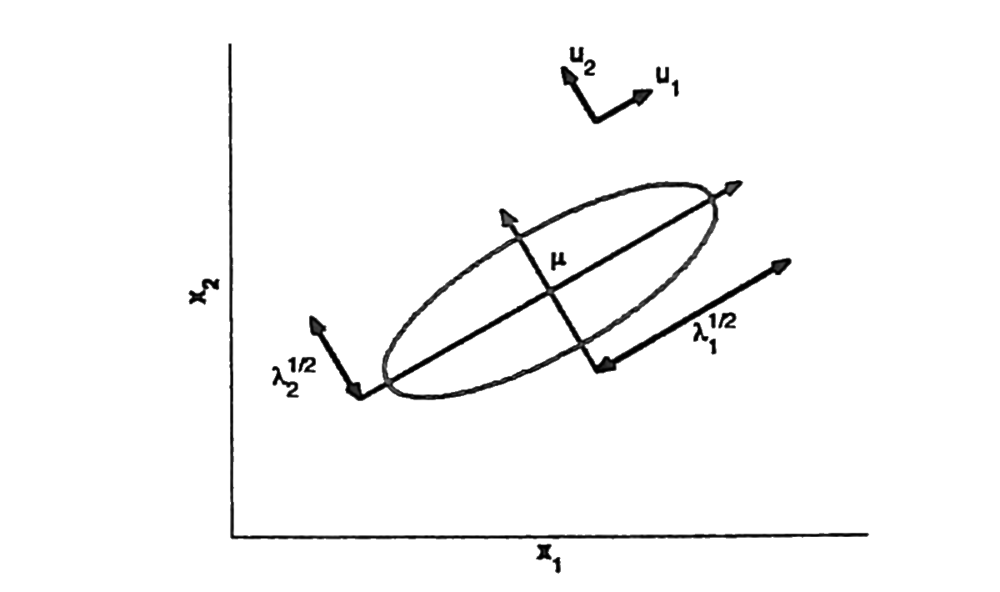

*Собственные векторы задают главные оси эллиптических линий уровня.*

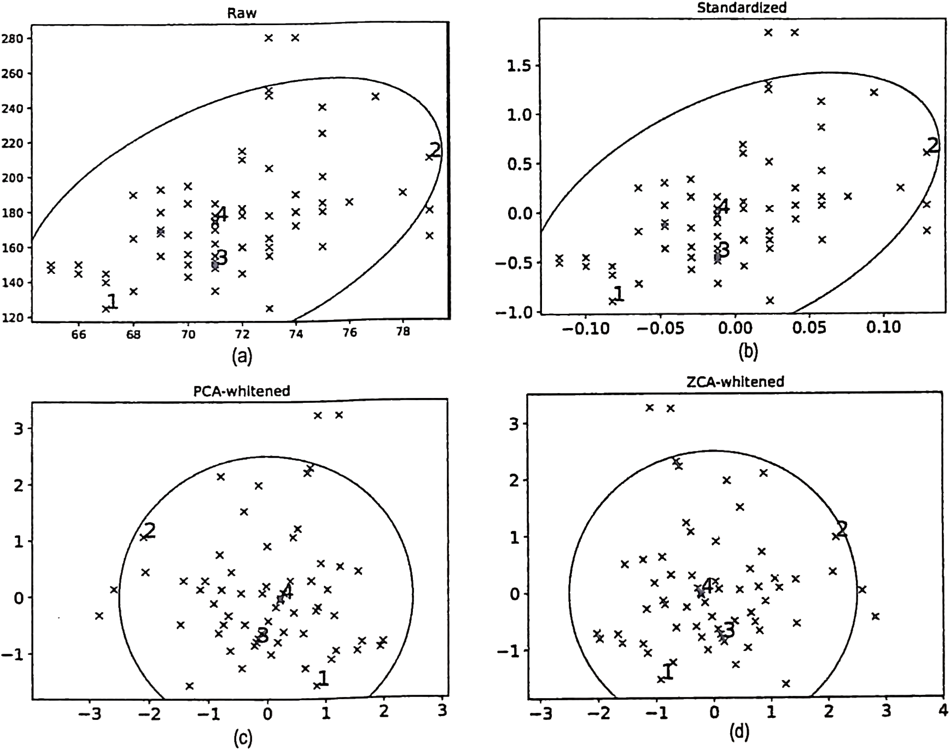

*Переход от исходных признаков к стандартизованному и отбеленному представлению.*


### Задание 9.1. Выполнить готовый алгоритм

В ноутбуке уже дан код, который:

1. центрирует и стандартизирует $\mathbf X$;
2. строит $\mathbf C$;
3. получает собственные значения и векторы командой `np.linalg.eigh`;
4. сортирует компоненты по убыванию $\lambda_k$;
5. проектирует данные на первую компоненту;
6. восстанавливает приближение исходных признаков;
7. визуализирует исходные и восстановленные точки.

- **[Python]** Выполните готовые ячейки сверху вниз. Самостоятельная реализация PCA не требуется.
- **[Markdown]** Выпишите размерности $\mathbf X$, $\mathbf Z$, $\mathbf C$, матрицы собственных векторов и одномерных координат.
- **[Интерпретация]** Ответьте:
  1. какую долю вариации объясняет первая компонента;
  2. почему коэффициенты двух признаков в ней близки по модулю;
  3. какие студенты имеют крайние значения новой координаты;
  4. что потеряно при восстановлении по одной компоненте;
  5. почему одновременная смена знака собственного вектора и всех координат не меняет решения.


#### Ваше решение

**Размерности.** $X,Z\in\mathbb R^{8\times2}$; $C\in\mathbb R^{2\times2}$; матрица собственных векторов $2\times2$; scores_1d — $8\times1$.

**Проверка и интерпретация.** Собственные значения около 1.98767 и 0.01233. Первая компонента объясняет 99.3834% дисперсии. После стандартизации дисперсии обоих признаков равны 1, а корреляция около 0.98767, поэтому веса первой компоненты одинаковы по модулю (около 0.7071). Аня и Илья имеют крайние координаты (при положительном направлении −1.7810 и 2.4078). При восстановлении теряется вариация вдоль второй компоненты (около 0.6166%), то есть индивидуальные отклонения от общего тренда активности. На графике восстановленные точки лежат на одной прямой. Одновременная смена знака направления и координат не меняет их произведение, а значит, и восстановление.

Размерности: (8, 2) (8, 2) (2, 2) (2, 2) (8, 1)
Ковариационная матрица:
 [[1.     0.9877]
 [0.9877 1.    ]]
Собственные значения: [1.9877 0.0123]
Доли объяснённой дисперсии: [0.9938 0.0062]
Первая компонента: [0.7071 0.7071]


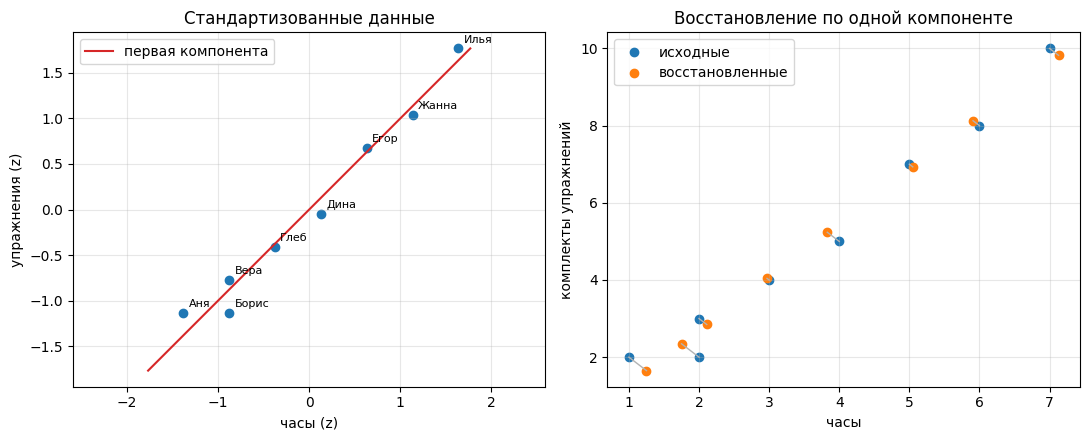

In [22]:
# Готовая реализация PCA: выполните её без изменений, затем интерпретируйте вывод.
mean_X = X.mean(axis=0)
scale_X = X.std(axis=0, ddof=0)
Z = (X - mean_X) / scale_X

C = Z.T @ Z / len(Z)
eigenvalues, eigenvectors = np.linalg.eigh(C)
order = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[order]
eigenvectors = eigenvectors[:, order]
explained_ratio = eigenvalues / eigenvalues.sum()

scores_1d = Z @ eigenvectors[:, :1]
Z_reconstructed = scores_1d @ eigenvectors[:, :1].T
X_reconstructed = Z_reconstructed * scale_X + mean_X

print("Размерности:", X.shape, Z.shape, C.shape, eigenvectors.shape, scores_1d.shape)
print("Ковариационная матрица:\n", C)
print("Собственные значения:", eigenvalues)
print("Доли объяснённой дисперсии:", explained_ratio)
print("Первая компонента:", eigenvectors[:, 0])

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].scatter(Z[:, 0], Z[:, 1], color="tab:blue")
for name, point in zip(student_names, Z):
    axes[0].annotate(name, point, xytext=(4, 4), textcoords="offset points", fontsize=8)
axis = np.linspace(-2.5, 2.5, 2)[:, None] * eigenvectors[:, 0]
axes[0].plot(axis[:, 0], axis[:, 1], color="tab:red", label="первая компонента")
axes[0].set_title("Стандартизованные данные")
axes[0].set_xlabel("часы (z)"); axes[0].set_ylabel("упражнения (z)")
axes[0].axis("equal"); axes[0].grid(alpha=0.3); axes[0].legend()

axes[1].scatter(X[:, 0], X[:, 1], label="исходные", color="tab:blue")
axes[1].scatter(X_reconstructed[:, 0], X_reconstructed[:, 1], label="восстановленные", color="tab:orange")
for original, restored in zip(X, X_reconstructed):
    axes[1].plot([original[0], restored[0]], [original[1], restored[1]], color="0.7", lw=1)
axes[1].set_title("Восстановление по одной компоненте")
axes[1].set_xlabel("часы"); axes[1].set_ylabel("комплекты упражнений")
axes[1].grid(alpha=0.3); axes[1].legend()
plt.tight_layout(); plt.show()


### Задание 9.2. Польза и ограничения

- **[Интерпретация]** Сформулируйте одним абзацем, когда сжатие двух признаков до одного полезно для визуализации или модели.
- **[Интерпретация]** Укажите не менее двух ограничений: PCA чувствителен к масштабу, описывает линейные направления и не использует целевой вектор $\mathbf y$ при выборе компонент.


#### Ваш ответ

Сжатие стандартизованной матрицы активности X размером 8×2 до одной координаты на студента полезно для визуализации и уменьшения числа коррелирующих признаков: корреляция равна примерно 0.9877, а первая компонента сохраняет 99.38% вариации. RMSE восстановления исходных чисел составляет около 0.1887 (смешанные единицы). PCA чувствителен к масштабу, поэтому требуется осмысленная стандартизация; он описывает линейные направления и может пропустить нелинейные зависимости. Кроме того, PCA не использует целевые баллы y, поэтому направление максимальной дисперсии не обязательно лучше всего предсказывает результат.

In [23]:
# Небольшая численная опора для ответа об ограничениях.
correlation = np.corrcoef(X.T)[0, 1]
reconstruction_rmse = np.sqrt(np.mean((X - X_reconstructed) ** 2))
print("Корреляция исходных признаков:", correlation)
print("RMSE восстановления по одной компоненте:", reconstruction_rmse)


Корреляция исходных признаков: 0.9876688294984395
RMSE восстановления по одной компоненте: 0.18867066835176535


## 10. Базовое SVD: малоранговое приближение изображения


### Зачем это нужно

Для любой матрицы $\mathbf A\in\mathbb R^{m\times n}$ сингулярное разложение имеет вид

$$
\mathbf A=\mathbf U\mathbf S\mathbf V^{\mathsf T}.
$$

Если оставить только первые $k$ сингулярных чисел и соответствующие столбцы, получится приближение ранга $k$:

$$
\mathbf A_k
=\mathbf U_{:,1:k}\mathbf S_{1:k,1:k}\mathbf V_{:,1:k}^{\mathsf T}.
$$

Оно хранит $k(m+n+1)$ чисел вместо $mn$. Чем больше $k$, тем точнее восстановление, но тем меньше выигрыш в объёме. Основы SVD см. на [с. 30–31](../02-linear-algebra/linear-algebra.pdf#page=30), усечённое SVD и оценку хранения — на [с. 33–34](../02-linear-algebra/linear-algebra.pdf#page=33).

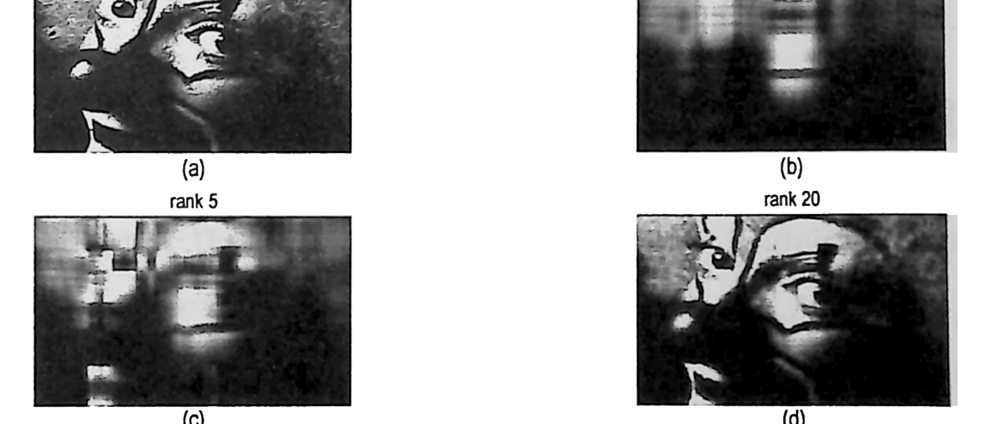

*Оригинал и приближения рангов 2, 5 и 20 из теоретического пособия.*


### Задание 10.1. Выполнить готовое SVD

Ноутбук загружает верхнее левое изображение из рис. 9, переводит его в оттенки серого и выполняет `np.linalg.svd`. Для $k\in\{2,5,20,50\}$ готовый код строит восстановление и считает относительную ошибку Фробениуса

$$
\varepsilon_k=
\frac{\lVert\mathbf A-\mathbf A_k\rVert_F}{\lVert\mathbf A\rVert_F}.
$$

- **[Python]** Выполните готовый код и получите четыре изображения, ошибки и оценки хранения.
- **[Markdown]** Составьте таблицу со столбцами: ранг $k$, относительная ошибка, количество хранимых чисел, доля от исходного объёма.
- **[Интерпретация]** Опишите, какие структуры появляются уже при $k=2$, какие детали добавляются при $k=5$ и $k=20$, и насколько заметно улучшение при $k=50$.
- **[Интерпретация]** Проверьте, что ошибка не возрастает с ростом $k$. Объясните, почему это ожидаемо.


#### Ваше решение

**Аналитическая выкладка / наблюдения.** Изображение взято из верхнего левого фрагмента рис. 9 PDF. После прореживания размер матрицы 126×263, исходный объём — 33138 чисел. Используем $k(126+263+1)=390k$.

| Ранг k | Относительная ошибка | Число хранимых значений | Доля исходного объёма |
|---:|---:|---:|---:|
| 2 | 0.41124 | 780 | 2.354% |
| 5 | 0.30479 | 1950 | 5.884% |
| 20 | 0.13901 | 7800 | 23.538% |
| 50 | 0.04309 | 19500 | 58.845% |

**Проверка и интерпретация.** При k=2 видны крупные светлые и тёмные области; при k=5 появляются приблизительные контуры лица, при k=20 лучше различимы глаз, очертания лица и фон. При k=50 контуры и текстура становятся чётче, но улучшение менее заметно, чем при переходе от малых рангов. Ошибка не возрастает, поскольку добавление очередной сингулярной компоненты уменьшает или оставляет неизменной сумму квадратов отброшенных сингулярных чисел. При этом объём хранения растёт. Оценка относится к числу значений, а не к фактическому размеру файла.

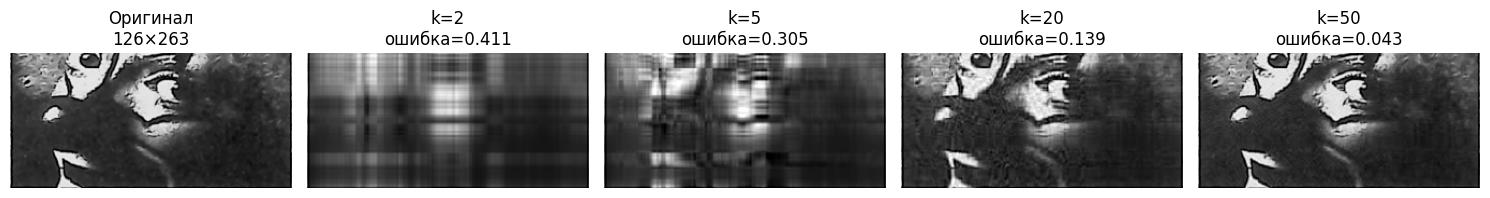

Исходное число значений: 33138
 k | отн. ошибка | хранить чисел | доля исходного
 2 |      0.41124 |           780 |        2.354%
 5 |      0.30479 |          1950 |        5.884%
20 |      0.13901 |          7800 |       23.538%
50 |      0.04309 |         19500 |       58.845%
Ошибка невозрастает: True


In [24]:
# Готовая демонстрация SVD на изображении из теоретического пособия.
import base64
import io
# Верхний левый фрагмент рис. 9 извлечён из PDF и встроен в ноутбук.
figure = plt.imread(io.BytesIO(base64.b64decode("...")), format="png")
gray = 0.2126 * figure[..., 0] + 0.7152 * figure[..., 1] + 0.0722 * figure[..., 2]

# Верхний левый фрагмент рис. 9; прореживание лишь уменьшает время вычисления.
image_matrix = gray[::2, ::2]
U, singular_values, Vt = np.linalg.svd(image_matrix, full_matrices=False)

ranks = [2, 5, 20, 50]
relative_errors = []
storage_numbers = []
m, n = image_matrix.shape

fig, axes = plt.subplots(1, 5, figsize=(15, 3.3))
axes[0].imshow(image_matrix, cmap="gray", vmin=0, vmax=1)
axes[0].set_title(f"Оригинал\n{m}×{n}")
axes[0].axis("off")

for ax, k in zip(axes[1:], ranks):
    approximation = (U[:, :k] * singular_values[:k]) @ Vt[:k, :]
    error = np.linalg.norm(image_matrix - approximation, ord="fro") / np.linalg.norm(image_matrix, ord="fro")
    storage = k * (m + n + 1)
    relative_errors.append(error)
    storage_numbers.append(storage)
    ax.imshow(approximation, cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"k={k}\nошибка={error:.3f}")
    ax.axis("off")

plt.tight_layout(); plt.show()

print("Исходное число значений:", m * n)
print(" k | отн. ошибка | хранить чисел | доля исходного")
for k, error, storage in zip(ranks, relative_errors, storage_numbers):
    print(f"{k:2d} | {error:12.5f} | {storage:13d} | {storage / (m*n):13.3%}")
print("Ошибка невозрастает:", np.all(np.diff(relative_errors) <= 1e-12))


### Задание 10.2. Связь PCA и SVD

В ноутбуке дополнительно выполняется SVD стандартизованной матрицы учебной активности $\mathbf Z$. Правые сингулярные векторы задают те же направления признаков, что и собственные векторы $\mathbf Z^{\mathsf T}\mathbf Z$.

- **[Python]** Сравните первый собственный вектор PCA с первой строкой $\mathbf V^{\mathsf T}$ с точностью до знака.
- **[Интерпретация]** Объясните результат без вывода формул: PCA описывает направления вариации данных, а SVD предоставляет удобный общий способ получить эти направления непосредственно из матрицы.


#### Ваше решение

**Проверка и интерпретация.** Модуль скалярного произведения первого направления PCA и первого правого сингулярного вектора равен 1 с точностью вычислений. Оба направления совпадают с точностью до знака. PCA описывает главные направления вариации стандартизованных данных, а SVD позволяет получить те же направления непосредственно из матрицы Z. Сингулярные числа характеризуют выраженность соответствующих направлений.

In [25]:
# SVD той же стандартизованной матрицы Z, которая использовалась в PCA.
U_data, s_data, Vt_data = np.linalg.svd(Z, full_matrices=False)
pca_direction = eigenvectors[:, 0]
svd_direction = Vt_data[0]
agreement_up_to_sign = abs(pca_direction @ svd_direction)

print("Направление PCA:", pca_direction)
print("Направление SVD:", svd_direction)
print("|скалярное произведение|:", agreement_up_to_sign)
print("Сингулярные числа:", s_data)


Направление PCA: [0.7071 0.7071]
Направление SVD: [0.7071 0.7071]
|скалярное произведение|: 1.0
Сингулярные числа: [3.9876 0.3141]


## 11. Итоговая интерпретация


### Задание 11.1. Карта понятий

- **[Markdown]** Напишите связный текст из 8–12 предложений, использовав термины: *вектор наблюдения*, *матрица данных*, *линейное отображение*, *ранг*, *система уравнений*, *проекция*, *наименьшие квадраты*, *главная компонента*, *сингулярное число*, *малоранговое приближение*.
- **[Интерпретация]** Для каждого из трёх итоговых результатов — регрессия, PCA, SVD — укажите:
  1. какой объект подаётся на вход;
  2. какой объект получается на выходе;
  3. какую практическую пользу даёт результат;
  4. какая информация при этом может быть потеряна или неправильно истолкована.


#### Ваш ответ

Вектор наблюдения описывает одного студента через часы практики и число выполненных комплектов. Матрица данных объединяет восемь таких векторов в строки. Линейное отображение позволяет получить новые признаки из исходных. Ранг показывает число независимых направлений в матрице. Система уравнений связывает неизвестные параметры с известными наблюдениями. Если точного решения нет, метод наименьших квадратов минимизирует сумму квадратов ошибок. Вектор предсказаний регрессии является проекцией результатов на пространство столбцов матрицы модели. Главная компонента PCA задаёт направление наибольшей вариации стандартизованных признаков. Сингулярное число показывает вклад соответствующего направления в SVD. Малоранговое приближение сохраняет основные структуры матрицы, уменьшая объём хранения ценой потери деталей.

| Метод | Вход | Выход | Польза | Потери и ограничения |
|---|---|---|---|---|
| Регрессия | D (8×3), y (8,) | три коэффициента, восемь прогнозов | оценка баллов, RMSE 0.5925 | остатки; высокий R² не доказывает причинность и обобщаемость |
| PCA | X (8×2), после стандартизации Z | координаты 8×1 и направление | сжатие, 99.38% вариации сохранено | теряется второе направление, не учитывается y |
| SVD | изображение 126×263 | U, сингулярные числа, Vᵀ и приближения | компромисс между точностью и объёмом | при малых рангах теряются мелкие детали |

## Что сдавать

Сдаётся заполненный студенческий ноутбук. Перед отправкой выполните все ячейки сверху вниз и убедитесь, что выводы сохранены.

Чек-лист:

- все задания **[Бумага]** перенесены в Markdown с промежуточными действиями;
- все ячейки **[Python]** выполняются без ошибок;
- размерности матриц указаны и согласованы;
- ответы **[Интерпретация]** относятся к конкретным полученным числам и графикам;
- невязка квадратной системы близка к нулю;
- для регрессии вычислены коэффициенты, остатки, SSE, RMSE и $R^2$;
- для PCA указана объяснённая дисперсия и разобрано восстановление;
- для SVD заполнена таблица рангов 2, 5, 20 и 50, а ошибка не возрастает;
- в последнем разделе дана единая связь между всеми этапами работы.


## Справка по синтаксису

В Markdown-ячейке формула внутри строки записывается как `$\mathbf y=\mathbf A\mathbf x$`, а отдельная формула — между двойными знаками доллара. В NumPy:

```python
A.shape                  # размерность массива
A.T                      # транспонирование
A @ B                    # матричное произведение
np.dot(a, b)             # скалярное произведение
np.linalg.norm(a)        # евклидова норма
np.linalg.det(A)         # определитель
np.linalg.matrix_rank(A) # ранг
np.linalg.solve(A, b)    # решение квадратной системы
np.linalg.lstsq(A, b, rcond=None)  # наименьшие квадраты
np.linalg.eigh(C)        # спектральное разложение симметричной матрицы
np.linalg.svd(A)         # сингулярное разложение
```

Все необходимые данные и изображения находятся в проекте; доступ к интернету не требуется.
